# Appendix D: interannual variability

One composite figure of the interannual panels from two notebooks. No new analysis; each data cell is copied from its source.

| row | panels | source |
|---|---|---|
| 1 | (a) 13-month smoothed anomalies of the wind-based indices and $W_{MLD}$, El Niño included | `v2.UI_comparison_winds`, merged figure (last version), panel (b) |
| 2 | (b) CUTI (+ $U^{Ek}$) vs $W_{MLD}$, (c) $Ek_t$ vs $W_{MLD}$, (d) AV vs $W_{MLD}$ | `v2.UI_comparison_winds`, same cell, "(c-e) interannual anomalies vs W_MLD, El Nino included in the fit" |
| 3 | (e) $U^{Ek}$ vs $N_{MLD}$, (f) MLD vs $N_{MLD}$ | `v3.UI_comparison`, bottom row of the N vs MLD / $U^{Ek}$ figure |

All inputs are read from `../data/`. All indices are in m² s⁻¹ per metre of coastline, 5–16°S row means (as in `UI_comparison` / `Latitudinal`): CUTI, $U^{Ek}$ and the $W_{MLD}$ reference (`W_L`) from `CUTI_BEUTI_HR_L_C.nc`; AV integrated across the 111 km band × row height ÷ coastline length; $Ek_t$ = cross-shore Ekman transport at the coast (already per metre of coastline).

Rows 1–2 use the v2 anomalies (climatology removed, 13-month centred mean, no detrending; fit over all months, nominal n).
Row 3 uses the v3 `ci_intervals` anomalies (climatology removed, linear trend removed, 13-month centred mean; fit over all months, $p$ from the $N_{eff}$ t-test).

In [9]:
from pathlib import Path
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.lines import Line2D
from matplotlib.legend_handler import HandlerTuple
from matplotlib.offsetbox import AnchoredOffsetbox, TextArea, VPacker
from scipy.stats import linregress

DATA = Path('../data')      # all inputs
FIG  = Path('Figures')      # output figures

mask_km = 109
lat1, lat0 = -16, -5

## Helper functions

In [10]:
def coastal_band_mask(ds, var='u10', target_width_km=111):
    """
    Create a coastal band mask with uniform cross-shore width in km.
    """
    da = ds[var]
    if 'time' in da.dims:
        da = da.mean(dim='time')

    valid2d = np.isfinite(da).values.astype(bool)
    lat_vals = ds['lat'].values
    lon_vals = ds['lon'].values
    dlon = np.abs(lon_vals[1] - lon_vals[0])  # grid spacing in degrees

    # Find coastline (easternmost valid cell per row)
    band = np.zeros_like(valid2d, dtype=bool)

    for j in range(valid2d.shape[0]):
        row = valid2d[j, :]
        ocean_cols = np.where(row)[0]
        if len(ocean_cols) == 0:
            continue

        # Coast = easternmost valid cell
        i_coast = ocean_cols[-1]

        # How many cells = target_width_km at this latitude?
        A = 6371.0  # km
        dx_km = A * np.cos(np.deg2rad(lat_vals[j])) * np.deg2rad(dlon)
        n_cells = int(np.round(target_width_km / dx_km))

        # Fill n_cells westward from coast
        i_start = max(i_coast - n_cells, 0)
        band[j, i_start:i_coast + 1] = True

    # Only keep cells that are actually ocean
    band = band & valid2d

    da_mask = xr.DataArray(band, dims=('lat', 'lon'),
                           coords={'lat': ds['lat'], 'lon': ds['lon']})
    return da_mask


# v2.UI_comparison_winds: anomalies used in rows 1-2 (El Nino included)
def prep_for_taylor(da, dim='time', window=13):
    """Climatology removal -> centred running mean -> drop NaNs."""
    clim = da.groupby(f'{dim}.month').mean(dim=dim)
    anom = da.groupby(f'{dim}.month') - clim
    return anom.rolling({dim: window}, center=True).mean().dropna(dim=dim)

### Interannual statistics of v3 (`Table2_ci_intervals` method, padding = 0), used in row 3

In [11]:
from scipy import stats

PAD = 0   # El Nino padding (months) -- no padding

# Extreme El Nino windows (masked AFTER smoothing, with a pad on each side)
NINO = [
    (pd.Timestamp('1982-06-01'), pd.Timestamp('1983-12-31')),
    (pd.Timestamp('1997-04-01'), pd.Timestamp('1998-07-31')),
]


# ----------------------------------------------------------------------------- helpers
def _to_series(obj, name=None):
    """Dataset/DataArray -> 1-D monthly series (mean over every dim except time).
    The time axis is put on month starts so series with different stamps
    (15th, end of month, cftime, ...) line up month by month."""
    if isinstance(obj, xr.Dataset):
        dvars = list(obj.data_vars)
        if len(dvars) != 1:
            raise ValueError(f'Dataset has {len(dvars)} variables {dvars}; '
                             'pass the DataArray you want, e.g. ds["chla"].')
        obj = obj[dvars[0]]
    other = [d for d in obj.dims if d != 'time']
    da = obj.mean(dim=other) if other else obj
    months = pd.to_datetime(da['time'].dt.strftime('%Y-%m-01').values)
    da = da.assign_coords(time=months)
    da = da.drop_vars([c for c in da.coords if c != 'time'])
    da.name = name or obj.name or 'series'
    return da


def _anomalies(da):
    """Remove the mean seasonal cycle (monthly climatology)."""
    clim = da.groupby('time.month').mean('time')
    return (da.groupby('time.month') - clim).drop_vars('month', errors='ignore')


def _detrend(da):
    """Remove a least-squares linear trend."""
    t = np.arange(da.sizes['time'], dtype=float)
    y = da.values.astype(float)
    ok = np.isfinite(y)
    b, a = np.polyfit(t[ok], y[ok], 1)
    return da - (a + b * t)


def acf_gaps(x, nlags):
    """Sample autocorrelation that tolerates NaN gaps.
    rho(k) = sum_i m_i m_{i+k} x_i x_{i+k} / sum_i m_i x_i^2   (x demeaned, m_i = 1 if valid)
    Pairs keep their true time separation; with no gaps this equals statsmodels acf(adjusted=False)."""
    x = np.asarray(x, float)
    x = x - np.nanmean(x)
    denom = np.nansum(x ** 2)
    out = np.empty(nlags + 1)
    for k in range(nlags + 1):
        a, b = x[:len(x) - k], x[k:]
        ok = ~np.isnan(a) & ~np.isnan(b)
        out[k] = np.sum(a[ok] * b[ok]) / denom
    return out


def _efolding(acf, thr):
    """First lag at which the autocorrelation drops below thr (1/e -> e-folding time)."""
    below = np.where(acf < thr)[0]
    if below.size == 0:
        raise ValueError('ACF never drops below the threshold; increase nlags.')
    return int(below[0])


def _en_mask(time, windows=NINO, pad_months=PAD):
    t = pd.DatetimeIndex(time.values)
    pad = pd.DateOffset(months=pad_months)
    m = np.zeros(t.size, dtype=bool)
    for s, e in windows:
        m |= (t >= s - pad) & (t <= e + pad)
    return m


def _trim_edges(da_x, da_y):
    """Drop only the leading/trailing NaNs left by the running mean (interior gaps stay)."""
    ok = np.where(np.isfinite(da_x.values) & np.isfinite(da_y.values))[0]
    sl = slice(ok[0], ok[-1] + 1)
    return da_x.isel(time=sl), da_y.isel(time=sl)


# ----------------------------------------------------------------------------- main
def ci_intervals(x, y, x_name=None, y_name=None, window=13, pad_months=PAD,
                 exclude_en=True, thr=1 / np.e, nlags=100, conf=0.95,
                 plot=False, verbose=False):
    """Correlation of two monthly series with a CI corrected for autocorrelation
    (Table2_ci_intervals). Besides the statistics, the dict also returns the
    smoothed series (x_sm, y_sm, NOT masked), their time axis t, the El Nino
    mask en and the pairs used for r (valid), for the scatter plots."""
    xs = _to_series(x, x_name)
    ys = _to_series(y, y_name)
    xn, yn = xs.name, ys.name
    xs, ys = xr.align(xs, ys, join='inner')
    if xs.sizes['time'] < 3 * window:
        raise ValueError(f'Only {xs.sizes["time"]} common months between {xn} and {yn}; '
                         'check the time axes.')

    # 1) anomalies + detrend (monthly, full record)
    x_dt = _detrend(_anomalies(xs))
    y_dt = _detrend(_anomalies(ys))

    # 2) running mean on the continuous series, trim the NaN edges
    x_sm = x_dt.rolling(time=window, center=True).mean()
    y_sm = y_dt.rolling(time=window, center=True).mean()
    x_sm, y_sm = _trim_edges(x_sm, y_sm)

    # 3) mask El Nino AFTER smoothing (NaN in place, nothing deleted)
    en = _en_mask(x_sm.time, pad_months=pad_months) if exclude_en else np.zeros(x_sm.sizes['time'], bool)
    xv = np.where(en, np.nan, x_sm.values)
    yv = np.where(en, np.nan, y_sm.values)
    valid = np.isfinite(xv) & np.isfinite(yv)
    xv[~valid] = np.nan
    yv[~valid] = np.nan

    # 4) statistics
    N = int(valid.sum())
    rho_hat = float(np.corrcoef(xv[valid], yv[valid])[0, 1])
    acf_x = acf_gaps(xv, nlags)
    acf_y = acf_gaps(yv, nlags)
    tau_x = _efolding(acf_x, thr)
    tau_y = _efolding(acf_y, thr)
    tau_eff = 2 * tau_x * tau_y / (tau_x + tau_y)
    N_eff = N / tau_eff

    if N_eff > 3:
        z = np.arctanh(rho_hat)
        se = 1 / np.sqrt(N_eff - 3)
        zc = stats.norm.ppf((1 + conf) / 2)
        ci = np.tanh([z - zc * se, z + zc * se])
    else:
        ci = np.array([np.nan, np.nan])
    dof = N_eff - 2
    t_stat = abs(rho_hat) * np.sqrt(dof / (1 - rho_hat ** 2))
    p = float(2 * stats.t.sf(t_stat, dof))

    res = dict(x=xn, y=yn, exclude_en=exclude_en, pad_months=pad_months,
               N=N, n_masked=int(en.sum()), tau_x=tau_x, tau_y=tau_y,
               tau_eff=tau_eff, N_eff=N_eff, rho_hat=rho_hat,
               ci=ci, ci_low=ci[0], ci_high=ci[1], p=p, R2=rho_hat ** 2,
               t=pd.DatetimeIndex(x_sm.time.values), x_sm=x_sm.values, y_sm=y_sm.values,
               en=en, valid=valid)

    if verbose:
        print(f'{xn} vs {yn}  (El Nino {"excluded, pad " + str(pad_months) + " mo" if exclude_en else "included"})')
        print(f'  N={N}  tau_x={tau_x}  tau_y={tau_y}  tau_eff={tau_eff:.1f}  N_eff={N_eff:.1f}')
        print(f'  r={rho_hat:.3f}  {int(conf*100)}% CI=[{ci[0]:.2f}, {ci[1]:.2f}]  '
              f'R2={rho_hat**2:.2f}  p={p:.2g}')

    # 5) plots
    if plot:
        fig, (ax1, ax3) = plt.subplots(2, 1, figsize=(11, 8),
                                       gridspec_kw=dict(height_ratios=[1.2, 1]))
        if exclude_en:
            pad = pd.DateOffset(months=pad_months)
            for i, (s, e) in enumerate(NINO):
                ax1.axvspan(s - pad, e + pad, color='0.9', zorder=0,
                            label=f'masked (EN +/- {pad_months} mo)' if i == 0 else None)
                ax1.axvspan(s, e, color='0.75', zorder=0,
                            label='El Nino' if i == 0 else None)
        ax1.plot(x_dt.time, x_dt, color='C0', lw=0.6, alpha=0.35)
        ax1.plot(x_sm.time, xv, color='C0', lw=2, label=f'{xn}')
        ax1.axhline(0, color='k', lw=0.5)
        ax1.set_ylabel(xn, color='C0')
        ax2 = ax1.twinx()
        ax2.plot(y_dt.time, y_dt, color='C1', lw=0.6, alpha=0.35)
        ax2.plot(y_sm.time, yv, color='C1', lw=2, label=f'{yn}')
        ax2.set_ylabel(yn, color='C1')
        h1, l1 = ax1.get_legend_handles_labels()
        h2, l2 = ax2.get_legend_handles_labels()
        ax1.legend(h1 + h2, l1 + l2, loc='upper left', fontsize=8)
        ax1.set_title(f'Detrended anomalies (thin: monthly, bold: {window}-month mean used for r)')

        lags = np.arange(nlags + 1)
        ax3.plot(lags, acf_x, color='C0', label=xn)
        ax3.plot(lags, acf_y, color='C1', label=yn)
        ax3.axhline(thr, color='k', lw=0.8, label='1/e' if np.isclose(thr, 1 / np.e) else f'{thr:.2f}')
        ax3.axhline(0, color='k', lw=0.5)
        ax3.axvline(tau_x, color='C0', ls='--', lw=1)
        ax3.axvline(tau_y, color='C1', ls='--', lw=1)
        ax3.set_xlabel('lag [months]')
        ax3.set_ylabel('autocorrelation')
        ax3.legend(fontsize=8)
        ax3.set_title(f'tau_x={tau_x}, tau_y={tau_y}, tau_eff={tau_eff:.1f}, N={N}, N_eff={N_eff:.1f} | '
                      f'r={rho_hat:.2f}, CI=[{ci[0]:.2f}, {ci[1]:.2f}], p={p:.1g}', fontsize=9)
        fig.tight_layout()
        plt.show()

    return res


# ----------------------------------------------------------------------------- v3 helpers
def prep_ia(da, exclude_en=False, pad_months=PAD, window=13, name=None):
    """One series through steps 1-3 of ci_intervals (anomalies -> detrend ->
    13-month centred mean, edges trimmed -> El Nino set to NaN if exclude_en).
    Used for the interannual time-series plots and spread statistics."""
    s = _to_series(da, name)
    sm = _detrend(_anomalies(s)).rolling(time=window, center=True).mean().dropna('time')
    if exclude_en:
        sm = sm.where(~_en_mask(sm.time, pad_months=pad_months))
    return sm


def ia_pair(x, y, exclude_en=True):
    """ci_intervals(x, y) plus the El Nino masks per event for the scatter colours.
    Returns res, x, y, en1, en2 (x/y: smoothed detrended anomalies, all months)."""
    res = ci_intervals(x, y, pad_months=PAD, exclude_en=exclude_en)
    t = res['t']
    en1 = np.asarray((t >= NINO[0][0]) & (t <= NINO[0][1]))
    en2 = np.asarray((t >= NINO[1][0]) & (t <= NINO[1][1]))
    return res, res['x_sm'], res['y_sm'], en1, en2


def _ptxt(pv):
    return "$p$ < 0.001" if pv < 0.001 else f"$p$ = {pv:.3f}"


def rp_label(res):
    """r^2 / p box text (p from the N_eff t-test)."""
    return f"$r^2$ = {res['R2']:.2f}\n{_ptxt(res['p'])}"


def print_res(name, res):
    print(f"{name:28s} r = {res['rho_hat']:+.3f}  95% CI = [{res['ci_low']:+.2f}, {res['ci_high']:+.2f}]  "
          f"r2 = {res['R2']:.2f}  p = {res['p']:.2g}  N = {res['N']}  N_eff = {res['N_eff']:.1f}")

## Data: wind-based indices and $W_{MLD}$ (rows 1–2, from `v2.UI_comparison_winds`)

In [12]:
AV = xr.open_dataset(DATA / 'AV.nc').AV.compute().sel(lat=slice(lat1, lat0))

Ek_t = xr.open_dataset(DATA / 'Winds_components_Lu.nc').U_ek_cross.isel(offshore=0)
Ek_t = (Ek_t.swap_dims({'coast_point': 'lat'})
         .drop_vars(['coast_point', 'lon', 'bearing', 'distance', 'f', 'offshore'])
         .rename('Ek_t')).sel(lat=slice(lat1, lat0)).compute()

# high-resolution CUTI, per metre of coastline (as in UI_comparison); the file is stored N -> S
hr = xr.open_dataset(DATA / 'CUTI_BEUTI_HR_L_C.nc').sortby('lat_band').compute().sel(lat_band=slice(lat1, lat0))
assert int(hr.L_coast.isnull().sum()) == 0
CUTI = hr.CUTI
# CROCO reference, m2/s: per row (area integral of W over the band boxes) / L, then the row mean (= WMLD_L of UI_comparison)
WMLD_L = hr.W_L.mean('lat_band').rename('W_MLD')

# AV (on CUTI's band, from AV.ipynb) per metre of coastline, as in Latitudinal: zonal integral over the 111 km band x row height / L_coast
# (row height dy is not stored in the _C file; CUTI_BEUTI_HR_L.nc has the same rows and L_coast and stores it)
R  = 6371000.0
L  = hr.L_coast.rename(lat_band='lat')
dy = (xr.open_dataset(DATA / 'CUTI_BEUTI_HR_L.nc').dy.sortby('lat_band')
        .sel(lat_band=slice(lat1, lat0)).rename(lat_band='lat'))
dx = R * np.cos(np.deg2rad(AV.lat)) * np.deg2rad(1 / 12)          # m
AV_L = ((AV * dx).sum('lon', min_count=1) * dy.reindex(lat=AV.lat, method='nearest', tolerance=0.02)
        / L.reindex(lat=AV.lat, method='nearest', tolerance=0.02)).rename('AV')   # m2/s per metre of coastline
# Ek_t: cross-shore Ekman transport at the coast, already m2/s per metre of coastline

# 13-month smoothed anomalies, El Nino included (m2/s)
wmld_wEN    = prep_for_taylor(WMLD_L)
AV_wEN      = prep_for_taylor(AV_L.mean('lat'))
Ekt_wEN     = prep_for_taylor(Ek_t.mean('lat'))
CUTI_wEN    = prep_for_taylor(CUTI.mean(dim='lat_band'))
Uek_wEN     = prep_for_taylor(hr.U_ek.mean(dim='lat_band'))

# row 1: (series, colour, label, line width)
ANOM_SERIES = [
    (wmld_wEN, 'black',      r'$W_{MLD}$', 2.0),
    (AV_wEN,   'dodgerblue', 'AV',         1.5),
    (Ekt_wEN,  'royalblue',  r'$EK_t$',    1.5),
    (CUTI_wEN, 'purple',     'CUTI',       1.5),
]
# row 2: (title, index, reference)
WIND_PAIRS = [('CUTI',     CUTI_wEN, wmld_wEN),
              (r'$Ek_t$',  Ekt_wEN,  wmld_wEN),
              ('AV',       AV_wEN,   wmld_wEN)]

## Data: $N_{MLD}$, MLD and $U^{Ek}$ (row 3, from `v3.UI_comparison`)

In [13]:
u = xr.open_dataset(DATA / 'UV_velocities.nc')[['u']].compute().transpose('time', 'lat', 'lon')
u = u.where(u != 0, np.nan)
mask = coastal_band_mask(u, 'u', mask_km).sel(lon=slice(-85, None), lat=slice(lat1, lat0))
del u

MLD = xr.open_dataset(DATA / 'MLD.nc').compute()
MLD = MLD.where(mask).sel(lon=slice(-85, None), lat=slice(lat1, lat0))

N = xr.open_dataset(DATA / 'Nitrogen.nc').compute()
N = N.where(N.TN_mld != 0, np.nan)
Nmask = coastal_band_mask(N, 'TN_mld', mask_km)
N = N.where(Nmask).sel(lon=slice(-85, None), lat=slice(lat1, lat0)).TN_mld
N['time'] = MLD.MLD.time            # same 432 monthly steps, different stamps

N_ts   = N.mean(dim=('lat', 'lon'))
MLD_ts = MLD.MLD.mean(dim=('lat', 'lon'))
UEK_ts = hr.U_ek.mean(dim='lat_band')

N_LABEL   = r'$N_{MLD}$ anomaly ($mmol\,N \ m^{-3}$)'
MLD_LABEL = r'MLD anomaly ($m$)'
UEK_LABEL = r'$U^{Ek}$ anomaly ($m^{2} \ s^{-1}$)'

# row 3: (title, x series, x label, corner of the r2/p box); y = N_MLD
N_PAIRS = [(r'$U^{Ek}$ vs $N_{MLD}$', UEK_ts, UEK_LABEL, 'upper right'),
           (r'MLD vs $N_{MLD}$',      MLD_ts, MLD_LABEL, 'lower left')]

## Panel functions

In [14]:
lz=2
LABEL_FS = 16+lz     # axis labels
TICK_FS  = 16+lz     # tick labels
TITLE_FS = 16+lz     # panel titles (a)-(f)
TXT_FS   = 13     # r2 / p boxes in (b)-(f)
LEG_A_FS = 16     # legend of (a)
LEG_FS   = 16     # shared legend next to (e)-(f) only
UNIT = r'$m^{2} \ s^{-1}$'
EN_WIN = [(pd.Timestamp('1982-06-01'), pd.Timestamp('1983-12-31')),
          (pd.Timestamp('1997-04-01'), pd.Timestamp('1998-07-31'))]

def _title(ax, s):
    ax.set_title(s, loc='left', fontsize=TITLE_FS, fontweight='bold')

def _rbox(ax, text, loc='upper left'):
    vert, horiz = loc.split()
    x, ha = (0.04, 'left') if horiz == 'left' else (0.96, 'right')
    y, va = (0.96, 'top') if vert == 'upper' else (0.04, 'bottom')
    ax.text(x, y, text, transform=ax.transAxes, va=va, ha=ha, fontsize=TXT_FS,
            bbox=dict(boxstyle='round', facecolor='white', alpha=0.85))


# ---------------- row 1 (v2 merged figure, panel b) ----------------
def plot_anomalies(ax):
    for sm, c, lab, lw_ in ANOM_SERIES:
        ax.plot(sm.time, sm, color=c, lw=lw_, label=lab)
    ax.axhline(0, color='gray', ls='--', lw=1)
    for t0, t1 in EN_WIN:
        ax.axvspan(t0, t1, facecolor='firebrick', alpha=0.15, zorder=0)
    ax.set_xlim(pd.Timestamp('1980-01-01'), pd.Timestamp('2016-01-01'))
    ax.set_ylim(-0.7, 0.7)
    ax.set_ylabel('anomaly (' + UNIT + ')', fontsize=LABEL_FS)
    ax.tick_params(axis='both', labelsize=TICK_FS, direction='in', size=6, width=1.5)
    ax.legend(fontsize=LEG_A_FS, ncol=4, frameon=False, loc='lower right')


# ---------------- row 2 (v2 merged figure, panels c-e) ----------------
BLACK_ALPHA = 0.35                           # transparency of the black (non-El Nino) dots in (b)-(f)
EN_ALPHA    = 0.6                           # transparency of the El Nino points (orange / red) in (b)-(f)
# per series: (colour, marker, EN82-83 marker, EN97-98 marker, size)
SC_LIM   = (-0.8, 0.8)                      # x and y limits of (b)-(d)
SC_TICKS = [-0.8, -0.4, 0, 0.4, 0.8]
STYLE_DEFAULT = ('black',     'o', 's', 'o', 25)
STYLE_UEK     = ('royalblue', '*', '*', '*', 60)

def _scatter_series(ax, test, ref, style, z=3, name=''):
    # z: drawing layer (points at z, fit line just above); U^Ek goes behind CUTI
    color, m, m_82, m_97, s = style
    t_, r_ = xr.align(test, ref, join='inner')
    df = pd.DataFrame({'time': pd.to_datetime(t_.time.values),
                       'test': t_.values.ravel(), 'ref': r_.values.ravel()}).dropna()
    x, y = df['ref'].to_numpy(), df['test'].to_numpy()
    tt  = df['time']
    en1 = ((tt >= EN_WIN[0][0]) & (tt <= EN_WIN[0][1])).to_numpy()
    en2 = ((tt >= EN_WIN[1][0]) & (tt <= EN_WIN[1][1])).to_numpy()

    ax.scatter(x, y, c=color, marker=m, edgecolors='none', s=s,
               alpha=BLACK_ALPHA if color == 'black' else 0.7, zorder=z)
    ax.scatter(x[en1], y[en1], c='tab:orange', marker=m_82, edgecolors='none',
               s=s * 1.5 if m_82 == '*' else 40, alpha=EN_ALPHA, zorder=z)
    ax.scatter(x[en2], y[en2], c='tab:red', marker=m_97, edgecolors='none',
               s=s * 1.5 if m_97 == '*' else 40, alpha=EN_ALPHA, zorder=z)

    sns.regplot(x=x, y=y, ax=ax, ci=95, scatter=False,
                line_kws={'color': color, 'lw': 2, 'zorder': z + 0.5})
    fit  = linregress(x, y)
    ptxt = "$p$ < 0.001" if fit.pvalue < 0.001 else f"$p$ = {fit.pvalue:.3f}"
    print(f"{name:5s}: slope = {fit.slope:.2f} ± {fit.stderr:.2f}, "
          f"r^2 = {fit.rvalue**2:.2f}, p = {fit.pvalue:.1e}, n = {len(x)}")
    return x, y, f"$r^2$ = {fit.rvalue**2:.2f}\n{ptxt}"

def plot_wind_scatter(ax, name, test, ref):
    x, y, label = _scatter_series(ax, test, ref, STYLE_DEFAULT, name=name)
    ax.plot(SC_LIM, SC_LIM, 'k--', lw=1, alpha=0.5, zorder=0)    # 1:1 line, corner to corner
    if name == 'CUTI':
        _, _, label_u = _scatter_series(ax, Uek_wEN, ref, STYLE_UEK, z=1, name='U_ek')
        # one rounded white box, U^Ek lines in blue, CUTI lines in black
        box = VPacker(children=[
            TextArea(label_u, textprops=dict(color='royalblue', fontsize=TXT_FS)),
            TextArea(label,   textprops=dict(color='black',     fontsize=TXT_FS)),
        ], align='left', pad=0, sep=4)
        anch = AnchoredOffsetbox(loc='lower right', child=box, pad=0.3, borderpad=0.5,
                                 frameon=True, bbox_to_anchor=(1.0, 0.0),
                                 bbox_transform=ax.transAxes)
        anch.patch.set_boxstyle('round')
        anch.patch.set_facecolor('white')
        anch.patch.set_alpha(0.85)
        ax.add_artist(anch)
    else:
        _rbox(ax, label)
    ax.set_xlabel(r'$W_{MLD}$ anomaly (' + UNIT + ')', fontsize=LABEL_FS)
    # same range and ticks on both axes for (b)-(d): all in m2/s and of the same magnitude
    ax.set_xlim(*SC_LIM); ax.set_ylim(*SC_LIM)
    ax.set_xticks(SC_TICKS); ax.set_yticks(SC_TICKS)
    # ax.grid(True, alpha=0.3)
    ax.tick_params(labelsize=TICK_FS)


# ---------------- row 3 (v3 N vs MLD / U^Ek figure, bottom row) ----------------
def plot_n_scatter(ax, x_ts, xlabel, box_loc='upper right'):
    res, x, y, en1, en2 = ia_pair(x_ts, N_ts, exclude_en=False)   # y = TN, x = MLD / U^Ek
    non_en = ~(en1 | en2)
    ax.scatter(x[non_en], y[non_en], c='black', marker='o', edgecolors='none', s=25, alpha=BLACK_ALPHA)
    ax.scatter(x[en1], y[en1], c='tab:orange', marker='s', edgecolors='none', s=40, alpha=EN_ALPHA)
    ax.scatter(x[en2], y[en2], c='tab:red', marker='o', edgecolors='none', s=40, alpha=EN_ALPHA)
    sns.regplot(x=x, y=y, ax=ax, ci=95, scatter=False, line_kws={'color': 'black', 'lw': 2})
    _rbox(ax, rp_label(res), loc=box_loc)
    ax.set_xlabel(xlabel, fontsize=LABEL_FS)
    ax.set_ylabel(N_LABEL, fontsize=LABEL_FS)
    ax.tick_params(labelsize=TICK_FS)
    return res

## Figure

CUTI : slope = 0.75 ± 0.02, r^2 = 0.81, p = 1.5e-154, n = 420
U_ek : slope = 0.79 ± 0.03, r^2 = 0.58, p = 1.2e-81, n = 420
$Ek_t$: slope = 0.74 ± 0.03, r^2 = 0.54, p = 1.5e-72, n = 420
AV   : slope = 0.55 ± 0.02, r^2 = 0.60, p = 1.4e-84, n = 420
$U^{Ek}$ vs $N_{MLD}$        r = -0.445  95% CI = [-0.67, -0.14]  r2 = 0.20  p = 0.0061  N = 420  N_eff = 36.6
MLD vs $N_{MLD}$             r = -0.294  95% CI = [-0.59, +0.07]  r2 = 0.09  p = 0.11  N = 420  N_eff = 30.1


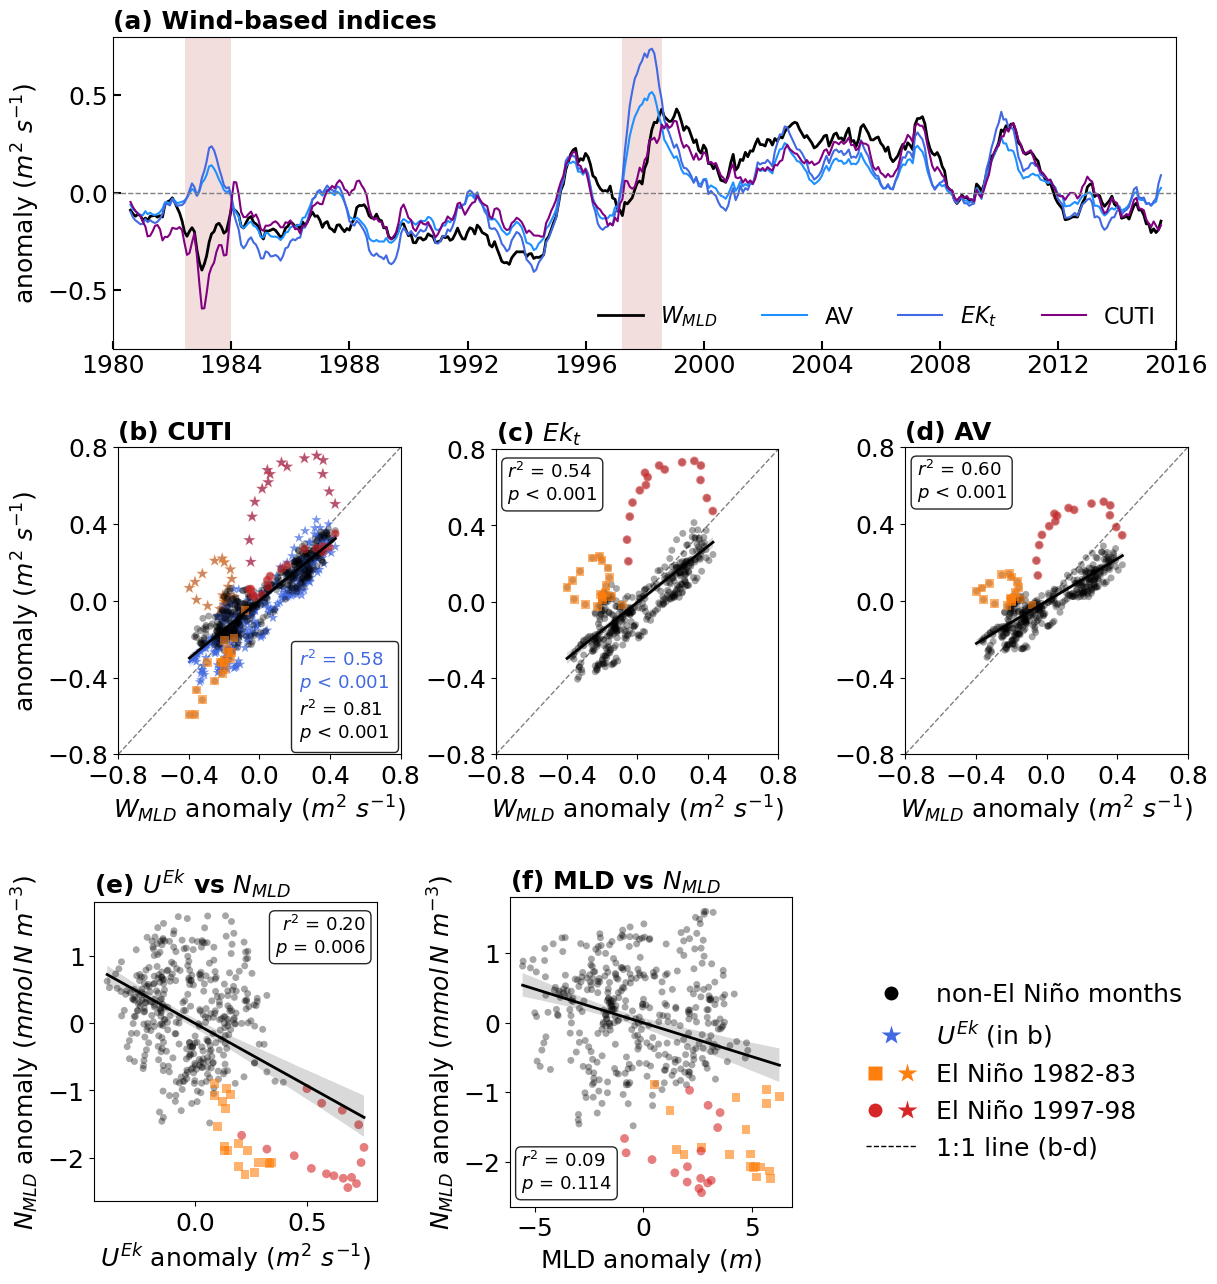

In [15]:
PANEL_WSPACE = 0.1

fig = plt.figure(figsize=(18*0.67, 19*0.67), layout='constrained')
sf1, sf2, sf3 = fig.subfigures(3, 1, height_ratios=[1, 1.1, 1.1], hspace=0.08)

# row 1: one panel over the full width
a = sf1.subplots()
plot_anomalies(a)
a.set_ylim(-0.8, 0.8)          # y range of (a), set here so it applies even if the panel-function cell was not re-run
_title(a, '(a) Wind-based indices')

# row 2: three independent panels
row2 = [s.subplots() for s in sf2.subfigures(1, 3, wspace=PANEL_WSPACE)]
for k, (ax, (name, test, ref)) in enumerate(zip(row2, WIND_PAIRS)):
    plot_wind_scatter(ax, name, test, ref)
    _title(ax, f'({"bcd"[k]}) {name}')
row2[0].set_ylabel('anomaly (' + UNIT + ')', fontsize=LABEL_FS)

# row 3: same column widths as row 2, the third slot holds the legend
s3 = sf3.subfigures(1, 3, wspace=PANEL_WSPACE)
row3 = [s.subplots() for s in s3[:2]]
for k, (ax, (title, x_ts, xlabel, box_loc)) in enumerate(zip(row3, N_PAIRS)):
    print_res(title, plot_n_scatter(ax, x_ts, xlabel, box_loc))
    _title(ax, f'({"ef"[k]}) {title}')

mk_ = lambda m, c, ms=10: Line2D([0], [0], marker=m, color='w', markerfacecolor=c,
                                 markeredgecolor='none', markersize=ms)
s3[2].legend([mk_('o', 'black'),
              mk_('*', 'royalblue', 15),
              (mk_('s', 'tab:orange'), mk_('*', 'tab:orange', 15)),
              (mk_('o', 'tab:red'),    mk_('*', 'tab:red', 15)),
              Line2D([0], [0], color='k', linestyle='--', lw=1)],
             ['non-El Niño months', r'$U^{Ek}$ (in b)', 'El Niño 1982-83', 'El Niño 1997-98', '1:1 line (b-d)'],
             handler_map={tuple: HandlerTuple(ndivide=None, pad=0.6)},
             loc='center', frameon=False, fontsize=LEG_FS + 2)

# (b)-(d): each sits in its own subfigure, so wider tick labels and the overhanging '0.8'
# left them narrower than (e)/(f). Widen them to the widths of (e)/(f) after the layout is done.
def _set_x(ax, x0, x1):
    """Move ax horizontally to display pixels x0..x1 (height and vertical position unchanged)."""
    inv = ax.figure.transSubfigure.inverted()
    p = ax.get_position()
    (l, _), (r, _) = inv.transform([(x0, 0), (x1, 0)])
    ax.set_position([l, p.y0, r - l, p.height])

fig.canvas.draw()                  # constrained layout places everything once ...
fig.set_layout_engine('none')      # ... then freeze it, so the widths set below stay
e_, f_ = [ax.get_window_extent() for ax in row3]
b_, c_, d_ = [ax.get_window_extent() for ax in row2]
_set_x(row2[0], b_.x0, b_.x0 + e_.width)        # (b) as wide as (e), left edge kept (room for its y label)
_set_x(row2[1], c_.x0, c_.x0 + f_.width)        # (c) as wide as (f), left edge kept
_set_x(row2[2], d_.x1 - f_.width, d_.x1)        # (d) as wide as (f), right edge kept

# fig.savefig(FIG / 'Appendix_D.pdf', bbox_inches='tight')
# fig.savefig(FIG / 'Appendix_D.png', dpi=300, bbox_inches='tight')
plt.show()